<a href="https://colab.research.google.com/github/fdegolla/MAT-422-Francisco-Degollado/blob/main/MAT422_HW_3_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# MAT 422 - Homework 3.7

**Name:** Francisco Degollado

## Artificial Neural Networks

### Topics
- 3.7.1 Mathematical Formulation
- 3.7.2 Activation Functions
- 3.7.3 Cost Function
- 3.7.4 Backpropagation
- 3.7.5 Backpropagation Algorithm

## 3.7.1 Mathematical Formulation

An artificial neural network is a machine learning model made up of interconnected neurons organized into layers. Each neuron receives inputs, multiplies them by weights, adds a bias, and applies an activation function to produce an output.

The mathematical formulation of a single neuron is:

$$
z = \sum_{i=1}^{n} w_i x_i + b
$$

The output of the neuron is:

$$
a = f(z)
$$

where:

- **xᵢ** represents the input values.
- **wᵢ** represents the weights.
- **b** represents the bias.
- **z** represents the weighted sum of inputs.
- **f(z)** represents the activation function.
- **a** represents the output of the neuron.

For an entire layer of neurons, the weighted sums can be calculated using matrix multiplication:

$$
z = Wx + b
$$

In this example, we will use Python to calculate the output of a single neuron using two input values, their corresponding weights, a bias, and the sigmoid activation function.

In [2]:

# Define the input values
x = np.array([2.0, 3.0])

# Define the weights and bias
w = np.array([0.5, -0.2])
b = 0.1

# Calculate the weighted sum
z = np.dot(w, x) + b

# Define the sigmoid activation function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Calculate the neuron output
a = sigmoid(z)

# Display the results
print("Input Values:", x)
print("Weights:", w)
print("Bias:", b)
print("Weighted Sum (z):", round(z, 4))
print("Neuron Output (a):", round(a, 4))


Input Values: [2. 3.]
Weights: [ 0.5 -0.2]
Bias: 0.1
Weighted Sum (z): 0.5
Neuron Output (a): 0.6225


## 3.7.2 Activation Functions

Activation functions determine the output of a neuron based on its weighted input. They introduce nonlinearity into neural networks, allowing the model to learn more complex relationships.

Three commonly used activation functions are Sigmoid, ReLU, and Tanh.

**1. Sigmoid Function**

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

The sigmoid function produces values between 0 and 1, making it useful for binary classification.

**2. Rectified Linear Unit (ReLU)**

$$
f(z)=\max(0,z)
$$

ReLU outputs zero for negative inputs and returns the input value for positive inputs. It is commonly used in hidden layers of neural networks.

**3. Hyperbolic Tangent (Tanh)**

$$
\tanh(z)=\frac{e^z-e^{-z}}{e^z+e^{-z}}
$$

The tanh function produces values between -1 and 1.

In this example, we will use Python to calculate and visualize these three activation functions.

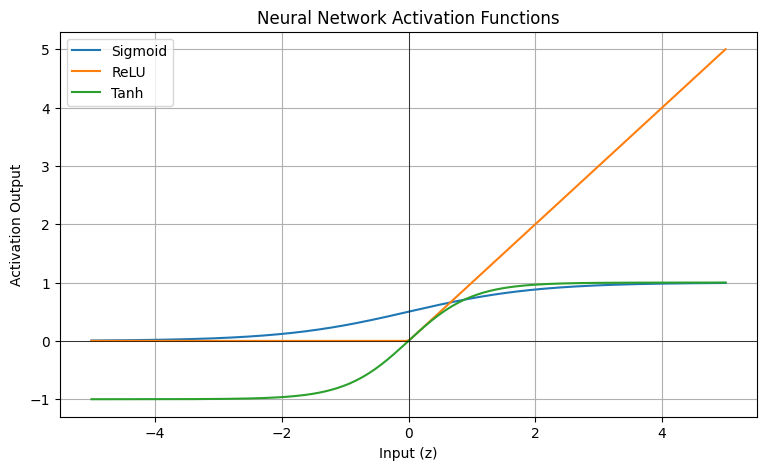

Input | Sigmoid | ReLU | Tanh
-----------------------------------
   -2 |  0.1192 |  0.0 | -0.9640
   -1 |  0.2689 |  0.0 | -0.7616
    0 |  0.5000 |  0.0 |  0.0000
    1 |  0.7311 |  1.0 |  0.7616
    2 |  0.8808 |  2.0 |  0.9640


In [4]:

# Create input values
z = np.linspace(-5, 5, 200)

# Define activation functions
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def relu(z):
    return np.maximum(0, z)

def tanh(z):
    return np.tanh(z)

# Calculate activation outputs
sigmoid_values = sigmoid(z)
relu_values = relu(z)
tanh_values = tanh(z)

# Plot activation functions
plt.figure(figsize=(9, 5))

plt.plot(z, sigmoid_values, label="Sigmoid")
plt.plot(z, relu_values, label="ReLU")
plt.plot(z, tanh_values, label="Tanh")

# Add labels and title
plt.xlabel("Input (z)")
plt.ylabel("Activation Output")
plt.title("Neural Network Activation Functions")

plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)

plt.legend()
plt.grid()
plt.show()


# Compare activation functions at selected inputs
test_values = np.array([-2, -1, 0, 1, 2])

print("Input | Sigmoid | ReLU | Tanh")
print("-" * 35)

for value in test_values:
    print(f"{value:5.0f} | "
          f"{sigmoid(value):7.4f} | "
          f"{relu(value):4.1f} | "
          f"{tanh(value):7.4f}")



## 3.7.3 Cost Function

A cost function measures how well a neural network's predictions match the actual values. During training, the goal is to minimize the cost by adjusting the weights and biases.

One commonly used cost function is Mean Squared Error (MSE):

$$
J=\frac{1}{m}\sum_{i=1}^{m}(y_i-\hat{y}_i)^2
$$

where:

- **m** represents the number of observations.
- **yᵢ** represents the actual value.
- **ŷᵢ** represents the predicted value.
- **J** represents the cost.

A smaller cost indicates that the predictions are closer to the actual values.

In this example, we will use Python to calculate the Mean Squared Error for a set of predictions and compare it with an improved set of predictions.

In [5]:

# Define actual values
y_actual = np.array([1, 0, 1, 1, 0])

# Define initial predicted values
y_pred_initial = np.array([0.7, 0.4, 0.6, 0.8, 0.3])

# Define improved predicted values
y_pred_improved = np.array([0.9, 0.2, 0.85, 0.95, 0.1])

# Calculate Mean Squared Error
def mse(y_actual, y_pred):
    return np.mean((y_actual - y_pred) ** 2)

initial_cost = mse(y_actual, y_pred_initial)
improved_cost = mse(y_actual, y_pred_improved)

# Display results
print("Initial Cost (MSE):", round(initial_cost, 4))
print("Improved Cost (MSE):", round(improved_cost, 4))
print("Cost Reduction:", round(initial_cost - improved_cost, 4))


Initial Cost (MSE): 0.108
Improved Cost (MSE): 0.017
Cost Reduction: 0.091


## 3.7.4 Backpropagation

Backpropagation is a method used to calculate the gradients of a neural network's cost function with respect to its weights and biases.

The process uses the chain rule to determine how each parameter contributes to the prediction error.

For a single neuron using the sigmoid activation function:

$$
z=wx+b
$$

$$
a=\sigma(z)=\frac{1}{1+e^{-z}}
$$

Using the squared-error cost function:

$$
J=\frac{1}{2}(a-y)^2
$$

The gradient with respect to the weight is:

$$
\frac{\partial J}{\partial w}
=(a-y)a(1-a)x
$$

The gradient with respect to the bias is:

$$
\frac{\partial J}{\partial b}
=(a-y)a(1-a)
$$

These gradients indicate how the cost changes when the weight or bias changes.

In this example, we will calculate the gradients of a single neuron using Python and demonstrate how the chain rule is applied.

In [6]:

# Define input, target, weight, and bias
x_bp = 2.0
y_bp = 1.0
w_bp = 0.5
b_bp = 0.1

# Forward propagation
z_bp = w_bp * x_bp + b_bp
a_bp = sigmoid(z_bp)

# Calculate the cost
cost_bp = 0.5 * (a_bp - y_bp) ** 2

# Backpropagation using the chain rule
dJ_da = a_bp - y_bp
da_dz = a_bp * (1 - a_bp)
dz_dw = x_bp
dz_db = 1

# Calculate gradients
dJ_dw = dJ_da * da_dz * dz_dw
dJ_db = dJ_da * da_dz * dz_db

# Display results
print("Neuron Output:", round(a_bp, 4))
print("Cost:", round(cost_bp, 4))
print("Gradient (dJ/dw):", round(dJ_dw, 4))
print("Gradient (dJ/db):", round(dJ_db, 4))


Neuron Output: 0.7503
Cost: 0.0312
Gradient (dJ/dw): -0.0936
Gradient (dJ/db): -0.0468


## 3.7.5 Backpropagation Algorithm

The backpropagation algorithm is used to train neural networks by repeatedly calculating gradients and updating weights and biases to reduce the cost function.

The process consists of forward propagation, cost calculation, backpropagation, and parameter updates.

The weight and bias are updated using gradient descent:

$$
w_{\text{new}}=w_{\text{old}}-\alpha\frac{\partial J}{\partial w}
$$

$$
b_{\text{new}}=b_{\text{old}}-\alpha\frac{\partial J}{\partial b}
$$

where:

- **α** represents the learning rate.
- **∂J/∂w** represents the gradient with respect to the weight.
- **∂J/∂b** represents the gradient with respect to the bias.

These steps repeat over multiple iterations until the cost decreases or a stopping condition is reached.

In this example, we will train a single sigmoid neuron using gradient descent and visualize how its cost changes over time.

Initial Cost: 0.031185
Final Cost: 0.001127
Final Weight: 1.2596
Final Bias: 0.4798
Final Neuron Output: 0.9525


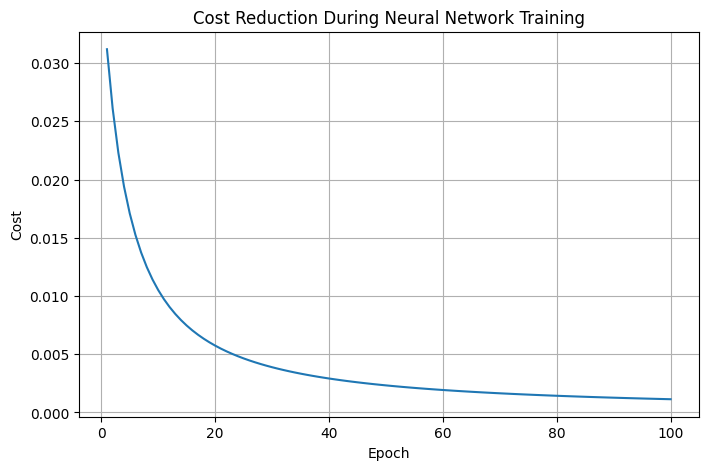

In [7]:

# Initialize the neuron parameters
x_train = 2.0
y_train = 1.0
w_train = 0.5
b_train = 0.1

# Set training parameters
learning_rate = 0.5
epochs = 100

# Store the cost at each iteration
cost_history = []

# Train the neuron
for epoch in range(epochs):

    # Forward propagation
    z_train = w_train * x_train + b_train
    a_train = sigmoid(z_train)

    # Calculate cost
    cost = 0.5 * (a_train - y_train) ** 2
    cost_history.append(cost)

    # Backpropagation
    error = a_train - y_train
    gradient = error * a_train * (1 - a_train)

    dJ_dw = gradient * x_train
    dJ_db = gradient

    # Update weight and bias
    w_train -= learning_rate * dJ_dw
    b_train -= learning_rate * dJ_db

# Calculate final output and cost
final_output = sigmoid(w_train * x_train + b_train)
final_cost = 0.5 * (final_output - y_train) ** 2

# Display results
print("Initial Cost:", round(cost_history[0], 6))
print("Final Cost:", round(final_cost, 6))
print("Final Weight:", round(w_train, 4))
print("Final Bias:", round(b_train, 4))
print("Final Neuron Output:", round(final_output, 4))

# Plot the cost over training iterations
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), cost_history)

plt.xlabel("Epoch")
plt.ylabel("Cost")
plt.title("Cost Reduction During Neural Network Training")
plt.grid()
plt.show()


### Multilayer Neural Network Example

A multilayer neural network contains an input layer, one or more hidden layers, and an output layer. Each layer calculates a weighted sum and applies an activation function before passing its output to the next layer.

For a neural network with one hidden layer, forward propagation is calculated as:

$$
z^{(1)}=W^{(1)}x+b^{(1)}
$$

$$
a^{(1)}=\sigma(z^{(1)})
$$

$$
z^{(2)}=W^{(2)}a^{(1)}+b^{(2)}
$$

$$
a^{(2)}=\sigma(z^{(2)})
$$

During backpropagation, the chain rule is used to calculate gradients from the output layer backward through the hidden layer.

For squared-error cost, the output-layer error is:

$$
\delta^{(2)}=(a^{(2)}-y)\sigma'(z^{(2)})
$$

The hidden-layer error is:

$$
\delta^{(1)}=(W^{(2)})^T\delta^{(2)}\odot\sigma'(z^{(1)})
$$

where the symbol ⊙ represents element-wise multiplication.

These errors are used to calculate the gradients of the weights and biases in each layer.

In this example, we will use Python to train a small neural network with two inputs, two hidden neurons, and one output neuron.

Initial Cost: 0.121079
Final Cost: 0.001582
Final Output: 0.9438


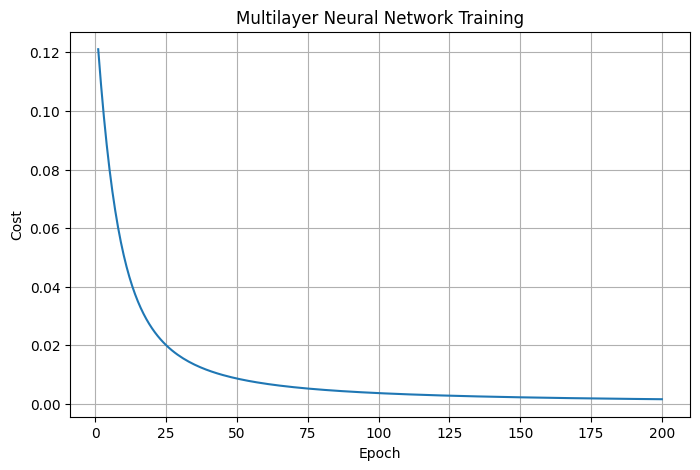

In [8]:

# Input and target output
x_multi = np.array([[1.0], [0.5]])
y_multi = np.array([[1.0]])

# Initialize weights and biases
W1 = np.array([[0.2, -0.3],
               [0.4,  0.1]])
b1 = np.zeros((2, 1))

W2 = np.array([[0.3, -0.2]])
b2 = np.zeros((1, 1))

# Training settings
learning_rate = 0.5
epochs = 200
multi_cost_history = []

# Train the multilayer neural network
for epoch in range(epochs):

    # Forward propagation
    z1 = W1 @ x_multi + b1
    a1 = sigmoid(z1)

    z2 = W2 @ a1 + b2
    a2 = sigmoid(z2)

    # Calculate cost
    cost = 0.5 * np.sum((a2 - y_multi) ** 2)
    multi_cost_history.append(cost)

    # Backpropagation: output layer
    delta2 = (a2 - y_multi) * a2 * (1 - a2)
    dW2 = delta2 @ a1.T
    db2 = delta2

    # Backpropagation: hidden layer
    delta1 = (W2.T @ delta2) * a1 * (1 - a1)
    dW1 = delta1 @ x_multi.T
    db1 = delta1

    # Update weights and biases
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

# Calculate final output
final_a1 = sigmoid(W1 @ x_multi + b1)
final_a2 = sigmoid(W2 @ final_a1 + b2)
final_multi_cost = 0.5 * np.sum((final_a2 - y_multi) ** 2)

# Display results
print("Initial Cost:", round(multi_cost_history[0], 6))
print("Final Cost:", round(float(final_multi_cost), 6))
print("Final Output:", round(float(final_a2[0, 0]), 4))

# Plot training cost
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), multi_cost_history)

plt.xlabel("Epoch")
plt.ylabel("Cost")
plt.title("Multilayer Neural Network Training")
plt.grid()
plt.show()


## Overall Results and Interpretation

This assignment demonstrated the main mathematical concepts of artificial neural networks using Python.

The mathematical formulation showed how a neuron uses inputs, weights, and a bias to calculate an output. The activation function examples showed how Sigmoid, ReLU, and Tanh produce different outputs from the same input values.

The cost function example demonstrated how Mean Squared Error measures prediction errors. The improved predictions reduced the cost from 0.108 to 0.017.

Backpropagation was used to calculate gradients using the chain rule. These gradients were then used to update the weights and biases during training.

After 100 training iterations, the single neuron's cost decreased from 0.031185 to 0.001127, and its output increased to 0.9525, getting closer to the target value of 1.

The multilayer neural network demonstrated backpropagation through a hidden layer. After 200 training iterations, the cost decreased from 0.121079 to 0.001582, and the final output reached 0.9438.